# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [12]:
# monte carlo

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

def monteCarlo(a, b, f, N):
    x_random = np.random.uniform(a, b, N)
    estimate = (b - a) * np.mean(f(x_random))
    return estimate


f1 = lambda x: np.sqrt(9 - 4 * x**2)
f2 = lambda x: -x**2 + 1
f3 = lambda x: np.sqrt(x) * np.cos(x)


print("Integral 1:", monteCarlo(0, 3/2, f1,1000))
print("Integral 2:", monteCarlo(-2, 2, f2,1000))
print("Integral 3:", monteCarlo(0, np.pi, f3,1000))  



Integral 1: 3.516554058140149
Integral 2: -1.6318529595507685
Integral 3: -0.9108040442405224


In [13]:
# Trapezoidal

def trapezoidal(a, b, f, N):
    # Generate N+1 evenly spaced points from a to b
    x = np.linspace(a, b, N + 1)
    y = f(x)
    
    h = (b - a) / N
    
   
    estimate = (h / 2) * (y[0] + 2 * np.sum(y[1:-1]) + y[-1])
    
    return estimate


f1 = lambda x: np.sqrt(9 - 4 * x**2)
f2 = lambda x: -x**2 + 1
f3 = lambda x: np.sqrt(x) * np.cos(x)


print("Integral 1:", trapezoidal(0, 3/2, f1,1000))
print("Integral 2:", trapezoidal(-2, 2, f2,1000))
print("Integral 3:", trapezoidal(0, np.pi, f3,1000))  



Integral 1: 3.5342499002749066
Integral 2: -1.333344
Integral 3: -0.8948683073575324


In [14]:
# Simpsons 1/3

def simpson13(a, b, f, n=1000):
    if n % 2 != 0:
        raise ValueError("n must be an even number for Simpson's 1/3 rule.")
    
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)
    
    estimate = (h / 3) * (y[0] + y[-1] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-1:2]))
    
    return estimate


f1 = lambda x: np.sqrt(9 - 4 * x**2)
f2 = lambda x: -x**2 + 1
f3 = lambda x: np.sqrt(x) * np.cos(x)

# Run the integrals (n must be even, 1000 works fine)
print("Integral 1:", simpson13(0, 3/2, f1, 1000))
print("Integral 2:", simpson13(-2, 2, f2, 1000))
print("Integral 3:", simpson13(0, np.pi, f3, 1000))

Integral 1: 3.534275396490739
Integral 2: -1.3333333333333335
Integral 3: -0.8948457649401638


In [15]:
# Simpsons 3/8

def simpson38(a,b,f,n):
    h= (b-a)/n
    sum= f(a)+f(b)

    for i in range(1,n):
        c = a+i*h
        if i%3==0:
            sum+=2*f(c)
        else:
            sum+=3*f(c)

    ans= (3*h/8)*sum
    return ans

    
f1 = lambda x: np.sqrt(9 - 4 * x**2)
f2 = lambda x: -x**2 + 1
f3 = lambda x: np.sqrt(x) * np.cos(x)

# Run the integrals (n must be even, 1000 works fine)
print("Integral 1:", simpson38(0, 3/2, f1, 1000))
print("Integral 2:", simpson38(-2, 2, f2, 1000))
print("Integral 3:", simpson38(0, np.pi, f3, 1000))


Integral 1: 3.53423258660329
Integral 2: -1.3303413359999992
Integral 3: -0.8934571396825044


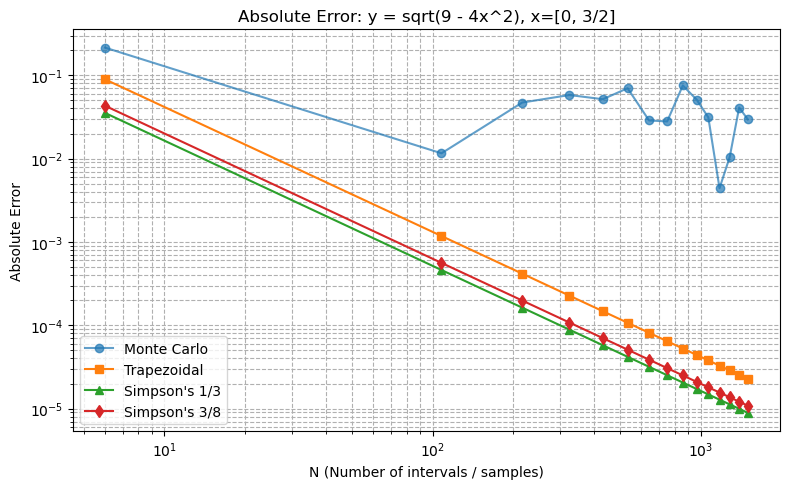

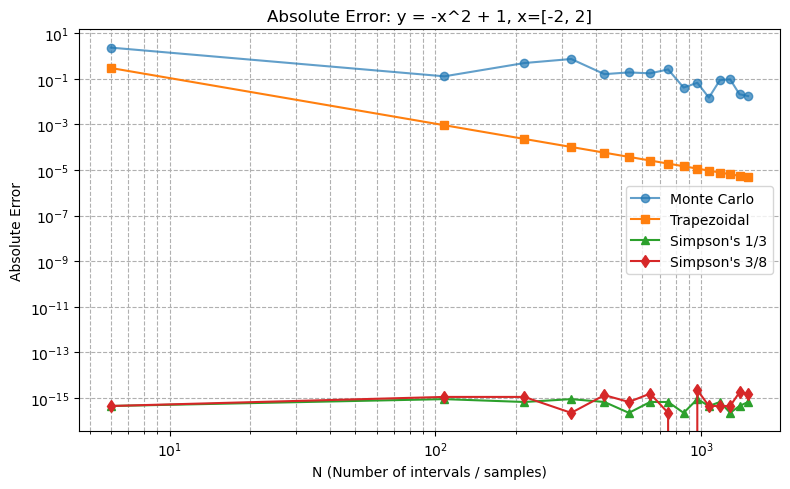

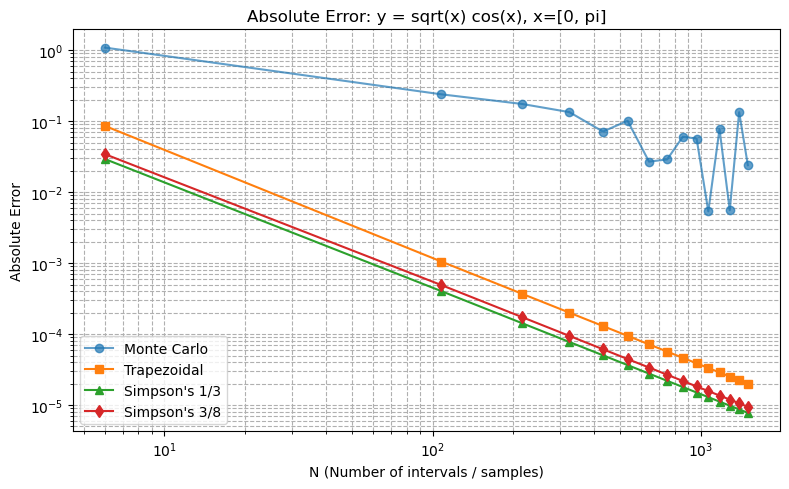

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# 1. Define functions and their respective boundaries[cite: 1]
funcs = [
    ("f1_sqrt_circle", lambda x: np.sqrt(9 - 4 * x**2), 0, 3/2, "y = sqrt(9 - 4x^2), x=[0, 3/2]"),
    ("f2_quadratic", lambda x: -x**2 + 1, -2, 2, "y = -x^2 + 1, x=[-2, 2]"),
    ("f3_sqrt_cos", lambda x: np.sqrt(x) * np.cos(x), 0, np.pi, "y = sqrt(x) cos(x), x=[0, pi]")
]

raw_N = np.linspace(6, 1500, 15, dtype=int)
N_vals = (raw_N // 6) * 6

# 4. Generate and save individual plots for each function
for filename_prefix, f, a, b, title_desc in funcs:
    # Get the true integral value [0] from scipy.integrate.quad
    true_val = quad(f, a, b)[0]
    
    mc_errors, trap_errors, s13_errors, s38_errors = [], [], [], []
    
    for n in N_vals:
        mc_errors.append(abs(monteCarlo(a, b, f, n) - true_val))
        trap_errors.append(abs(trapezoidal(a, b, f, n) - true_val))
        s13_errors.append(abs(simpson13(a, b, f, n) - true_val))
        s38_errors.append(abs(simpson38(a, b, f, n) - true_val))
        
    # Create a separate figure for each function
    plt.figure(figsize=(8, 5))
    plt.loglog(N_vals, mc_errors, 'o-', label='Monte Carlo', alpha=0.7)
    plt.loglog(N_vals, trap_errors, 's-', label='Trapezoidal')
    plt.loglog(N_vals, s13_errors, '^-', label="Simpson's 1/3")
    plt.loglog(N_vals, s38_errors, 'd-', label="Simpson's 3/8")
    
    plt.title(f"Absolute Error: {title_desc}")
    plt.xlabel('N (Number of intervals / samples)')
    plt.ylabel('Absolute Error')
    plt.grid(True, which="both", ls="--")
    plt.legend()
    plt.tight_layout()
    
    # Save the plot as a PNG file
    filename = f"{filename_prefix}_error_plot.png"
    plt.savefig(filename, dpi=300)
    
  

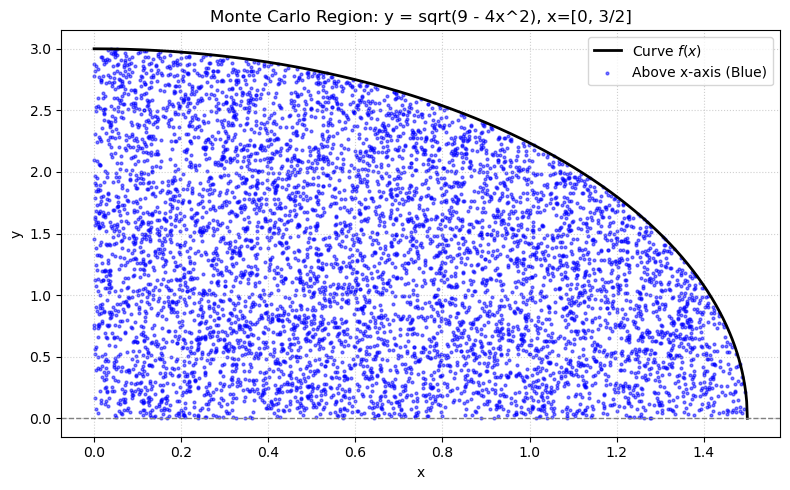

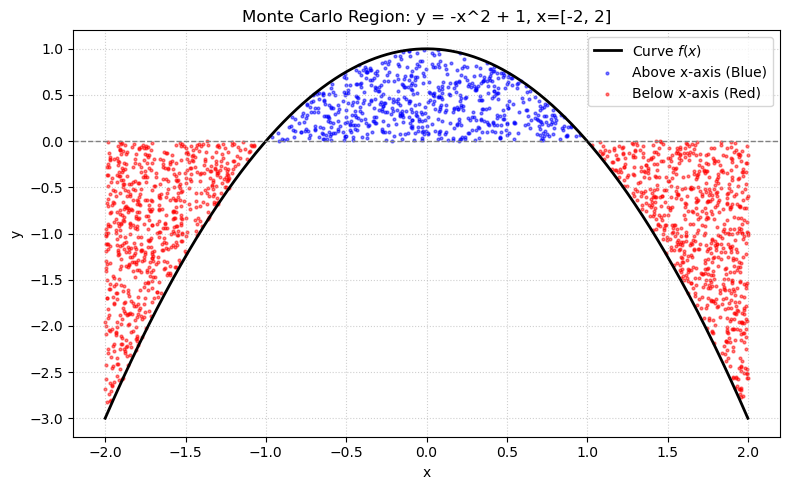

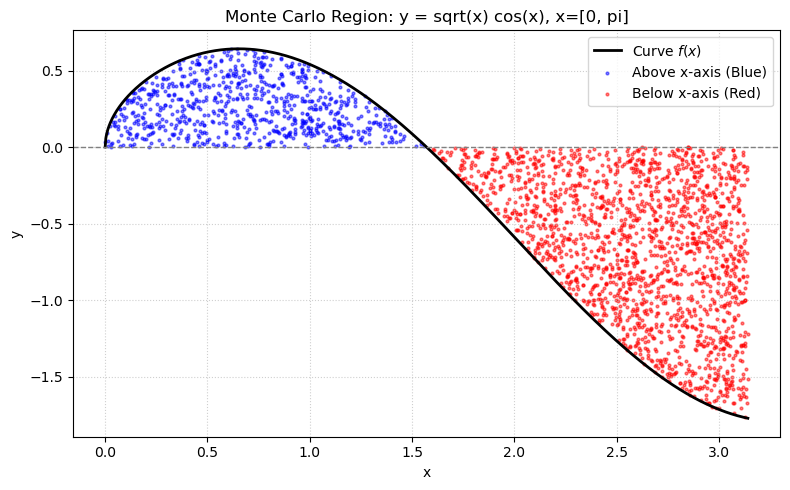

In [26]:

funcs = [
    ("f1", lambda x: np.sqrt(9 - 4 * x**2), 0, 3/2, "y = sqrt(9 - 4x^2), x=[0, 3/2]"),
    ("f2", lambda x: -x**2 + 1, -2, 2, "y = -x^2 + 1, x=[-2, 2]"),
    ("f3", lambda x: np.sqrt(x) * np.cos(x), 0, np.pi, "y = sqrt(x) cos(x), x=[0, pi]")
]

N = 10000 


for filename_prefix, f, a, b, title_desc in funcs:
  
    x_rand = np.random.uniform(a, b, N)
    
  
    x_dense = np.linspace(a, b, 1000)
    y_dense = f(x_dense)
    y_min, y_max = min(0, np.min(y_dense)), max(0, np.max(y_dense))
    
    
    y_range = y_max - y_min if y_max != y_min else 1.0
    y_rand = np.random.uniform(y_min - 0.1 * y_range, y_max + 0.1 * y_range, N)
    
    f_vals = f(x_rand)
    
    above = (y_rand >= 0) & (y_rand <= f_vals) & (f_vals >= 0)
    below = (y_rand <= 0) & (y_rand >= f_vals) & (f_vals < 0)
    
    x_above, y_above = x_rand[above], y_rand[above]
    x_below, y_below = x_rand[below], y_rand[below]
    
    
    plt.figure(figsize=(8, 5))
    
  
    plt.plot(x_dense, y_dense, 'k-', linewidth=2, label='Curve $f(x)$')
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    
 
    if len(x_above) > 0:
        plt.scatter(x_above, y_above, color='blue', s=4, alpha=0.5, label='Above x-axis (Blue)')
    if len(x_below) > 0:
        plt.scatter(x_below, y_below, color='red', s=4, alpha=0.5, label='Below x-axis (Red)')
        
    plt.title(f"Monte Carlo Region: {title_desc}")
    plt.xlabel('x')
    plt.ylabel('y')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    
    
    plt.savefig("carlo.png", dpi=300)
    